In [20]:
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt 

import warnings
warnings.filterwarnings("ignore")

In [11]:
patience_data = pd.read_csv("global_cancer_patients_2015_2024.csv")

In [12]:
patience_data.head()

,Patient_ID,Age,Gender,Country_Region,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Cancer_Type,Cancer_Stage,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
0,PT0000000,71,Male,UK,2021,6.4,2.8,9.5,0.9,8.7,Lung,Stage III,62913.44,5.9,4.92
1,PT0000001,34,Male,China,2021,1.3,4.5,3.7,3.9,6.3,Leukemia,Stage 0,12573.41,4.7,4.65
2,PT0000002,80,Male,Pakistan,2023,7.4,7.9,2.4,4.7,0.1,Breast,Stage II,6984.33,7.1,5.84
3,PT0000003,40,Male,UK,2015,1.7,2.9,4.8,3.5,2.7,Colon,Stage I,67446.25,1.6,3.12
4,PT0000004,43,Female,Brazil,2017,5.1,2.8,2.3,6.7,0.5,Skin,Stage III,77977.12,2.9,3.62


In [13]:
patience_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Patient_ID             50000 non-null  object 
 1   Age                    50000 non-null  int64  
 2   Gender                 50000 non-null  object 
 3   Country_Region         50000 non-null  object 
 4   Year                   50000 non-null  int64  
 5   Genetic_Risk           50000 non-null  float64
 6   Air_Pollution          50000 non-null  float64
 7   Alcohol_Use            50000 non-null  float64
 8   Smoking                50000 non-null  float64
 9   Obesity_Level          50000 non-null  float64
 10  Cancer_Type            50000 non-null  object 
 11  Cancer_Stage           50000 non-null  object 
 12  Treatment_Cost_USD     50000 non-null  float64
 13  Survival_Years         50000 non-null  float64
 14  Target_Severity_Score  50000 non-null  float64
dtypes:

In [14]:
patience_data.duplicated().sum()

np.int64(0)

In [18]:
patience_data.describe()

,Age,Year,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level,Treatment_Cost_USD,Survival_Years,Target_Severity_Score
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,54.421540,2019.480520,5.001698,5.010126,5.010880,4.989826,4.991176,52467.298239,5.006462,4.951207
std,20.224451,2.871485,2.885773,2.888399,2.888769,2.881579,2.894504,27363.229379,2.883335,1.199677
min,20.000000,2015.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5000.050000,0.000000,0.900000
25%,37.000000,2017.000000,2.500000,2.500000,2.500000,2.500000,2.500000,28686.225000,2.500000,4.120000
50%,54.000000,2019.000000,5.000000,5.000000,5.000000,5.000000,5.000000,52474.310000,5.000000,4.950000
75%,72.000000,2022.000000,7.500000,7.500000,7.500000,7.500000,7.500000,76232.720000,7.500000,5.780000
max,89.000000,2024.000000,10.000000,10.000000,10.000000,10.000000,10.000000,99999.840000,10.000000,9.160000


## **Descriptive Analysis**

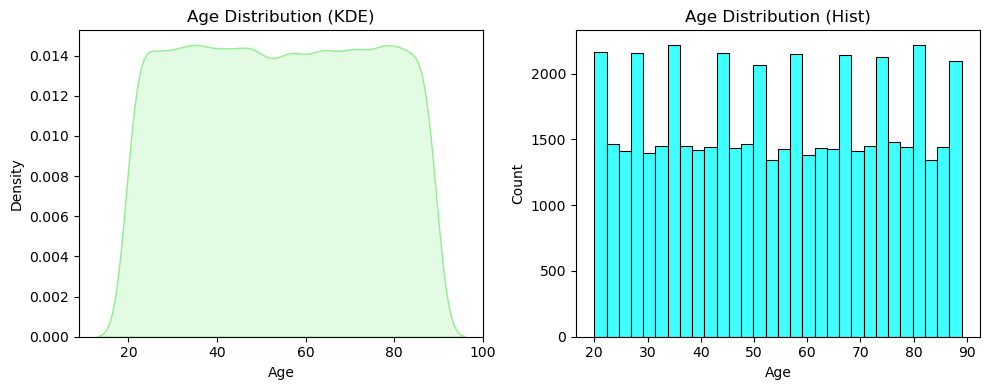

In [21]:
plt.figure(figsize=(10, 4))

plt.subplot(1,2,1)
sns.kdeplot(patience_data["Age"], fill=True, color="lightgreen")
plt.title("Age Distribution (KDE)")

plt.subplot(1,2,2)
sns.histplot(patience_data["Age"], bins=30, kde=False, color="cyan")
plt.title("Age Distribution (Hist)")

plt.tight_layout()
plt.show()

In [22]:
patience_data['Age'].describe()

count    50000.000000
mean        54.421540
std         20.224451
min         20.000000
25%         37.000000
50%         54.000000
75%         72.000000
max         89.000000
Name: Age, dtype: float64

**INFERENCE** 


* Range: 20 to 89 years
* Mean Age: 54.42 years
* Standard Deviation: 20.22
* Interquartile Range (IQR): 37(Q1) to 72(Q3)
  
This suggests a broad representation of both young and elderly patients in the datasets, which support age-based comparative analysis.


In [23]:
# Gender Column
patience_data['Gender'].value_counts()

Gender
Male      16796
Female    16709
Other     16495
Name: count, dtype: int64

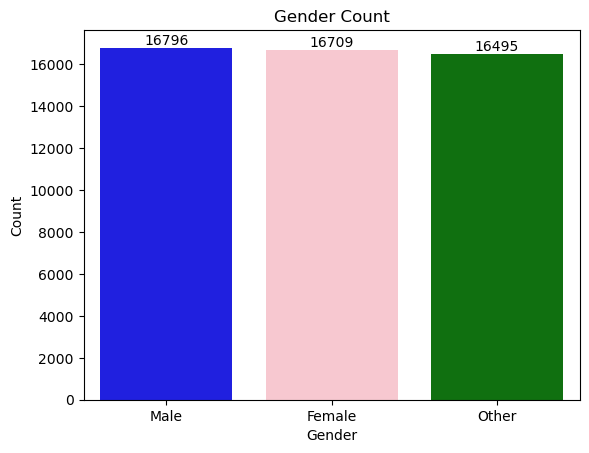

In [24]:
sns.barplot(x = patience_data['Gender'].value_counts().index,
           y = patience_data['Gender'].value_counts().values,
           palette=['blue','pink','green'])

for i, v in enumerate(patience_data['Gender'].value_counts()):
    plt.text(i,v, str(v), ha='center', va='bottom')

plt.title('Gender Count')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

The dataset contains three gender categories(Male, Female, Other) with most common being Male(16796 records). Gender distribution is suffcient for evaluating gender specific survival trends and severity outcomes.

In [28]:
country_counts = patience_data['Country_Region'].value_counts()
country_counts

Country_Region
Australia    5092
UK           5060
USA          5060
India        5040
Germany      5024
Russia       5017
Brazil       5004
Pakistan     4926
China        4913
Canada       4864
Name: count, dtype: int64

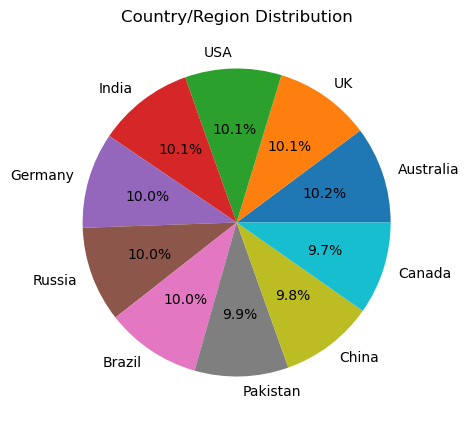

In [35]:
plt.figure(figsize=(5,5))
plt.pie(
    x = country_counts.values,
    labels = country_counts.index,
    autopct = "%1.1f%%"
)
plt.title("Country/Region Distribution")
plt.show()

Patients come from 10 different countries/regions, with Australia being the most represented (5,092 patients). Number of data points for each country is almost same. This diversity enables cross-country comparison of cancer outcomes and treatment economic.

In [36]:
cancerType_counts = patience_data['Cancer_Type'].value_counts()
cancerType_counts

Cancer_Type
Colon       6376
Prostate    6308
Leukemia    6266
Liver       6249
Skin        6231
Cervical    6222
Breast      6189
Lung        6159
Name: count, dtype: int64

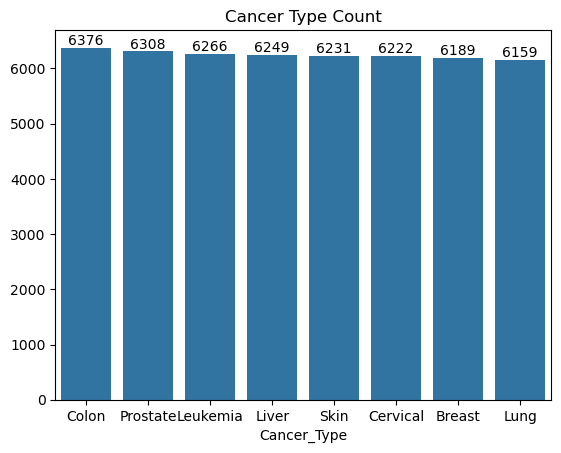

In [37]:
sns.barplot(
    x = cancerType_counts.index,
    y = cancerType_counts.values
)


for i, v in enumerate(cancerType_counts):
    plt.text(i, v, str(v), ha='center', va='bottom')


plt.title('Cancer Type Count')
plt.show()

We have in  total 8 types of cancer , with each cancer having approx same number of data points under the label , most common cnacers are colon cancer followed by Prostate cancer

In [39]:
cancerStage_counts = patience_data['Cancer_Stage'].value_counts()
cancerStage_counts

Cancer_Stage
Stage II     10124
Stage I      10046
Stage III    10008
Stage IV      9933
Stage 0       9889
Name: count, dtype: int64

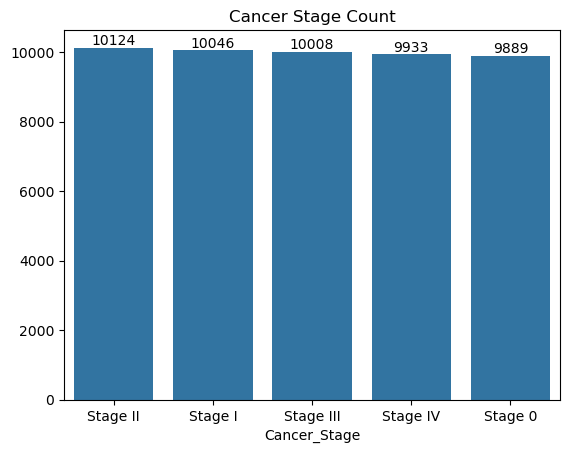

In [40]:
sns.barplot(
    x = cancerStage_counts.index,
    y = cancerStage_counts.values
)

for i, v in enumerate(cancerStage_counts):
    plt.text(i, v, str(v), ha='center', va='bottom')

plt.title('Cancer Stage Count')
plt.show()

Cancer Stage have 5 stages with values ranging from 0 to 4 , with stage 2 the most common one , and each stage have  almost same number of data pointsn under its label.

In [43]:
patience_data['Treatment_Cost_USD'].describe()

count    50000.000000
mean     52467.298239
std      27363.229379
min       5000.050000
25%      28686.225000
50%      52474.310000
75%      76232.720000
max      99999.840000
Name: Treatment_Cost_USD, dtype: float64

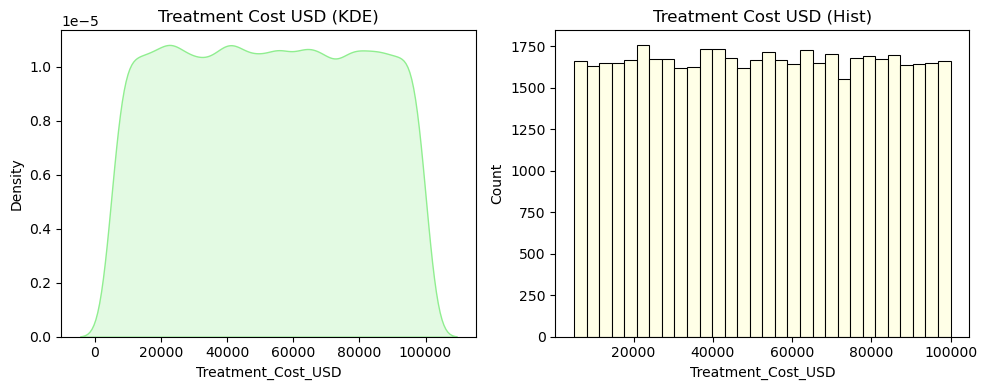

In [44]:
plt.figure(figsize=(10, 4))

plt.subplot(1,2,1)
sns.kdeplot(patience_data["Treatment_Cost_USD"], fill=True, color="lightgreen")
plt.title("Treatment Cost USD (KDE)")

plt.subplot(1,2,2)
sns.histplot(patience_data["Treatment_Cost_USD"], bins=30, kde=False, color="lightyellow")
plt.title("Treatment Cost USD (Hist)")

plt.tight_layout()
plt.show()

Treatment cost USD have no skewness , and there are almost same number of data points under each bin as observed by histogram

In [47]:
#Analyzing Risk Factors

risk_factors = ['Genetic_Risk', 'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']

risk_factors_summary = patience_data[risk_factors].agg(['mean', 'std', 'min', 'max'])

risk_factors_summary


,Genetic_Risk,Air_Pollution,Alcohol_Use,Smoking,Obesity_Level
mean,5.001698,5.010126,5.010880,4.989826,4.991176
std,2.885773,2.888399,2.888769,2.881579,2.894504
min,0.000000,0.000000,0.000000,0.000000,0.000000
max,10.000000,10.000000,10.000000,10.000000,10.000000


These variables have nearly identical means and standard deviations, indicating they were likely designed on the same standardized scale. They are essential in studying interaction effects (e.g., genetic risk × smoking) on survival.

## **Determine the relationship between risk factors and cancer severity**

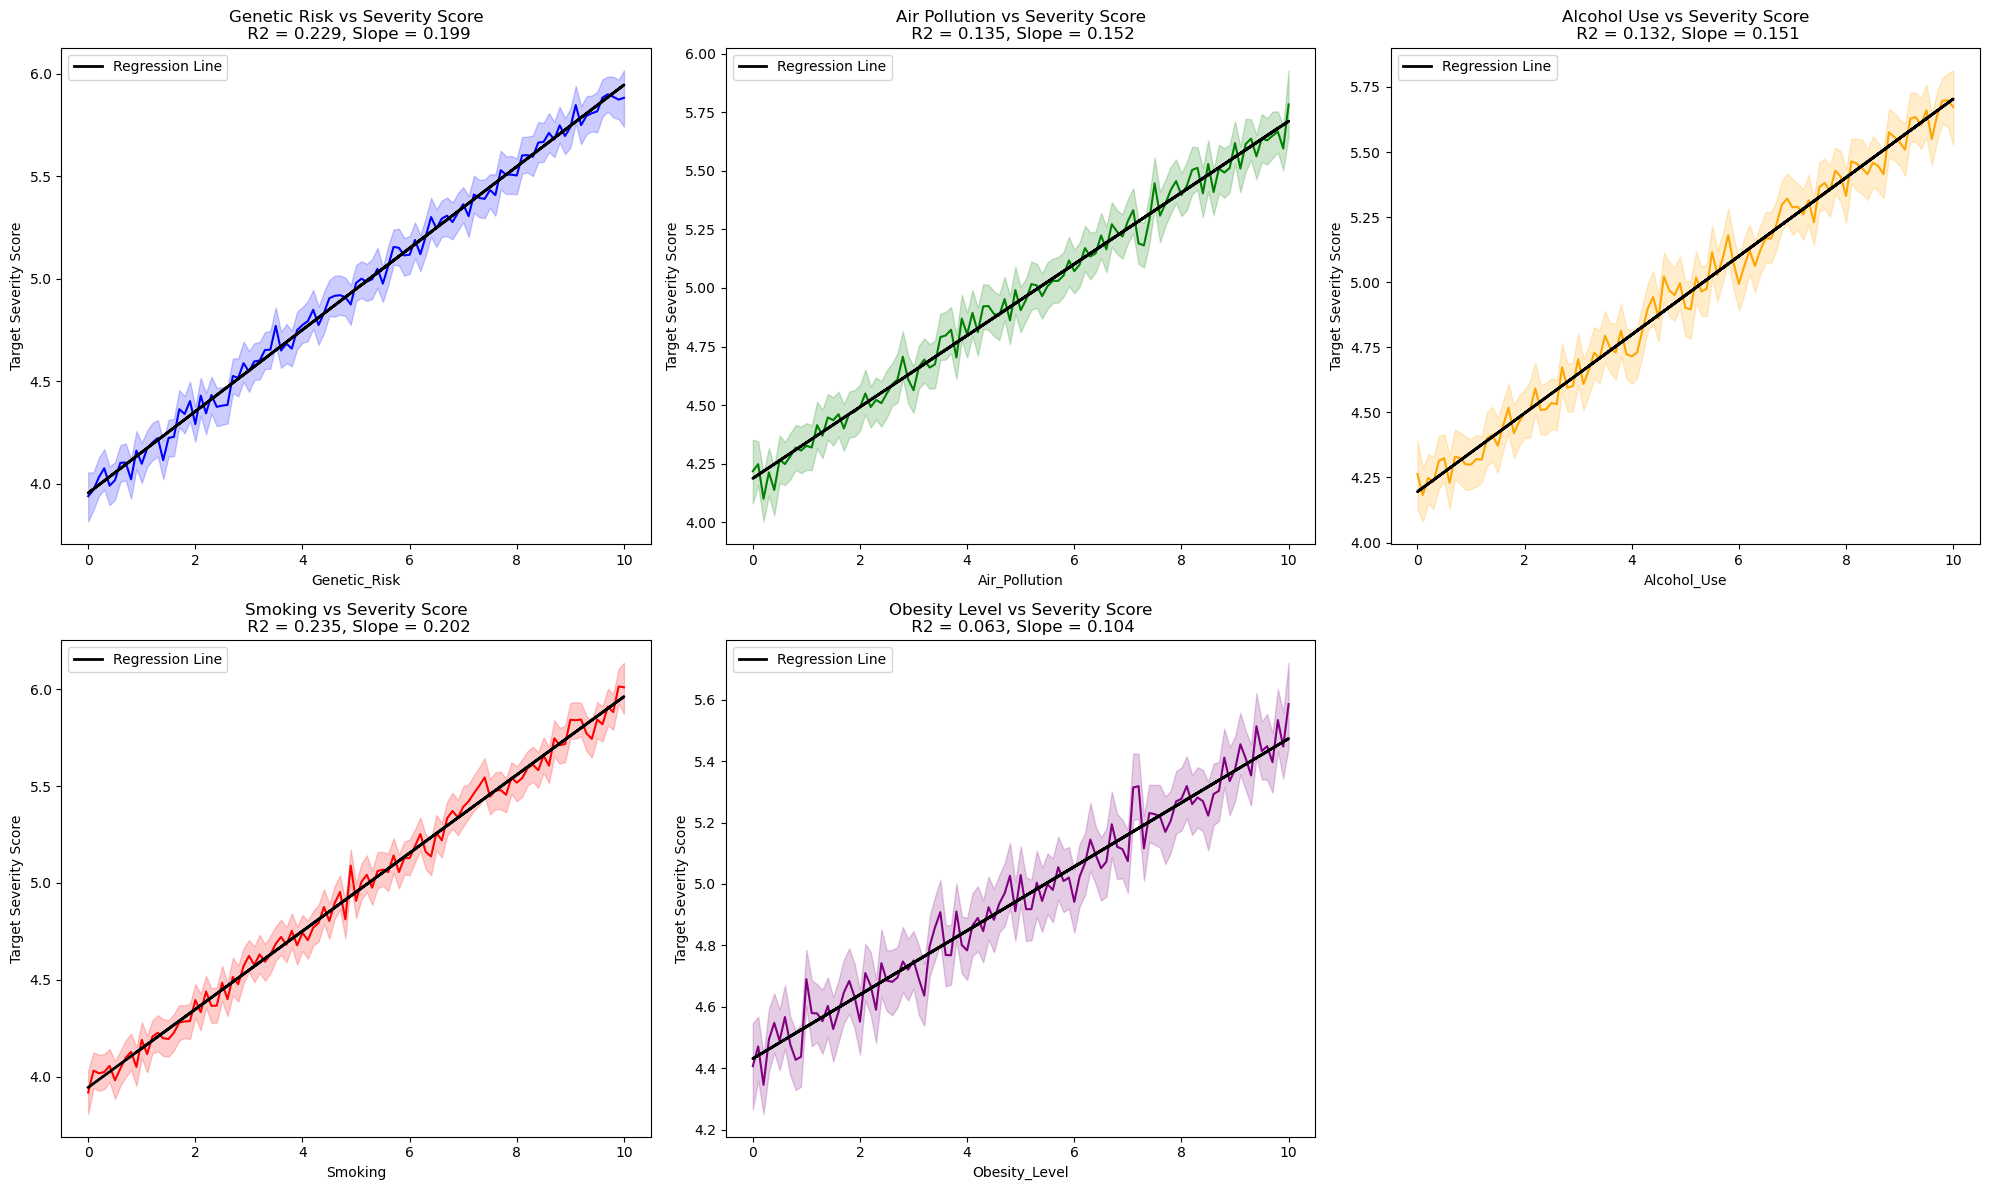

In [58]:
from scipy.stats import linregress


titles = ['Genetic Risk','Air Pollution', 'Alcohol Use', 'Smoking', 'Obesity Level']
colors = ['blue', 'green', 'orange', 'red', 'purple']

plt.figure(figsize=(20,12))
for i, (factor, title, color) in enumerate(zip(risk_factors, titles, colors), 1):
    plt.subplot(2,3,i)

    x = patience_data[factor]
    y = patience_data['Target_Severity_Score']
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    r_squared = r_value ** 2

    sns.lineplot(x = factor, y = 'Target_Severity_Score', data = patience_data, color = color)
    plt.plot(x, x*slope+intercept, color='black', linewidth=2, label = 'Regression Line')
    plt.title(f"{title} vs Severity Score\n R2 = {r_squared:.3f}, Slope = {slope:.3f}")
    plt.xlabel(factor)
    plt.ylabel("Target Severity Score")
    plt.legend()

    # mx+c

plt.tight_layout()
plt.show()

To understand the contribution of various risk factors to cancer severity, line plots were generated for five primary variables: Genetic Risk, Air Pollution, Alcohol Use, Smoking, and Obesity Level, plotted against the Target Severity Score.
All graphs reveal a positive relationship, indicating that as the level of a particular risk factor increases, the corresponding severity of the condition also tends to rise. However, the degree of association—measured by the slope and tightness of the confidence interval—varies across factors.

**Genetic Risk vs Target Severity Score
R² = 0.23 :**
A weak linear relationship. Only 23% of the variability in Target_Severity_Score can be explained by Genetic_Risk. This suggests that other factors likely play a larger role in influencing the severity score.
Slope = 0.20:
A positive slope indicates that as Genetic_Risk increases, the Target_Severity_Score also tends to increase. For each unit increase in Genetic_Risk, the target severity score increases by 0.20 units. However, because the R² is relatively low.

**Air Pollution vs Target Severity Score
R² = 0.13 :**
A very weak relationship. Only 13% of the variance in Target_Severity_Score can be explained by Air_Pollution, meaning that this factor has a limited effect on the target variable.
Slope = 0.15:
A positive slope means that as air pollution increases, the severity score slightly increases. But, due to the low R², this relationship is weak and unreliable as a predictor for the target severity.

**Alcohol Use vs Target Severity Score
R² = 0.13 :**
Similarly, the relationship between Alcohol_Use and Target_Severity_Score is also weak. Only 13% of the variation in the target score is explained by alcohol use.
Slope = 0.15:
The positive slope indicates that increased alcohol use correlates with a slight increase in target severity. However, like air pollution, the weak R² suggests other factors have a much stronger influence on the target.

**Smoking vs Target Severity Score
R² = 0.23 :**
A weak relationship, similar to Genetic_Risk. Smoking explains only 23% of the variance in the target score, leaving the majority of the variation to be explained by other factors.
Slope = 0.20:
The positive slope implies that as smoking increases, the target severity score increases as well. This relationship is similar to that of genetic risk, but with a weak linear association (low R²).

**Obesity Level vs Target Severity Score
R² = 0.06 :**
The weakest relationship among all factors. Only 6% of the variation in the target score is explained by obesity level, suggesting that obesity has a minimal effect on the target variable.
Slope = 0.10:
A positive slope, indicating a slight increase in the severity score as obesity level increases. However, due to the very low R², this is a weak and unreliable relationship.

**Key Takeaways :**
Weak Linear Relationships:
The R² values for all risk factors are relatively low, ranging from 0.06 to 0.23. This indicates that while there is some relationship between these risk factors and the Target_Severity_Score, it is weak. These factors alone do not explain much of the variation in the target variable.

Positive Trends:
All the slope values are positive, suggesting that as each risk factor increases, the Target_Severity_Score tends to increase as well. However, because the R² values are low, this increase is not strongly consistent across all data points.

Other Influences:
The low R² values imply that other, unmeasured factors are likely contributing to the variation in Target_Severity_Score. The risk factors you examined are only weakly correlated with the target and are not reliable predictors on their own.

Next Steps:
Given the weak explanatory power of these individual factors, it might be useful to explore other variables or more complex models that could account for more of the variation in the Target_Severity_Score. This could include interactions between risk factors, adding new features, or applying more sophisticated regression techniques.